# 04 · Clustering Algorithms
**Module 5 (CO4)** — Bike Sharing Demand EDA

| Syllabus topic | Section |
|---|---|
| Spectral clustering | §2 |
| Document clustering | §3 |
| Minimum Spanning Tree clustering | §4 |
| Model-based clustering & the Expectation-Maximization algorithm | §5 |
| Hierarchical agglomerative (model-based) clustering | §6 |
| Outlier detection using clustering | §7 |

**Question:** are there natural *types of days* in the bike-sharing data, and which days are unusual?

In [1]:
import sys
import warnings
sys.path.append("../src")

# k-NN similarity graphs can have disconnected pieces (e.g. the two moons, or rare storm days);
# sklearn warns about it, but the clustering still works as intended.
warnings.filterwarnings("ignore", message="Graph is not fully connected")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import SpectralClustering, KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

from utils import set_style, save_fig, load_clean_daily, load_clean_hourly, RAW, PALETTE

set_style()
daily = load_clean_daily()
hourly = load_clean_hourly()

## 1. Build the feature matrices
1. **Daily hourly-profile matrix** (731 × 24): rentals in each hour of each day, divided by the day's total. Each row describes the *shape* of a day.
2. **Daily weather–demand matrix** (731 × 4): temperature, humidity, windspeed and total rentals, standardised (z-scores), because clustering uses distances and the variables have very different scales.

In [2]:
profile = hourly.pivot_table(index="date", columns="hour", values="cnt", aggfunc="sum").fillna(0)
profile.index = pd.to_datetime(profile.index)
shape = profile.div(profile.sum(axis=1), axis=0)

features = ["temp", "humidity", "windspeed", "cnt"]
X = StandardScaler().fit_transform(daily[features])
print("profile:", shape.shape, "| weather-demand:", X.shape)

profile: (731, 24) | weather-demand: (731, 4)


## 2. Spectral clustering
K-means assumes compact, round clusters. **Spectral clustering** instead:
1. builds a **similarity graph** between points (e.g. k-nearest neighbours or an RBF kernel),
2. computes the **graph Laplacian** $L = D - W$ and its first *k* eigenvectors,
3. runs k-means on those eigenvectors.

This lets it find clusters that are *connected* but not round. A quick illustration on the classic two-moons data:

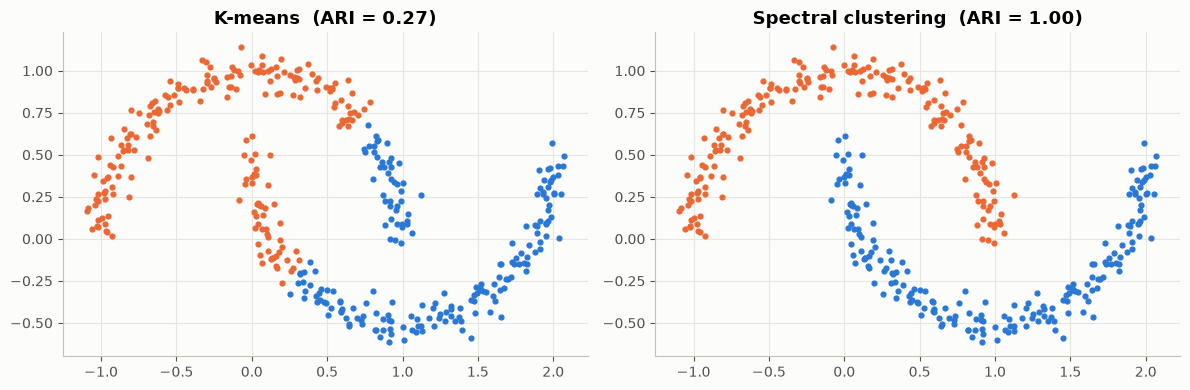

In [3]:
Xm, ym = make_moons(400, noise=0.06, random_state=0)
km_lab = KMeans(2, n_init=10, random_state=0).fit_predict(Xm)
sc_lab = SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0).fit_predict(Xm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, lab, title in [(axes[0], km_lab, "K-means"), (axes[1], sc_lab, "Spectral clustering")]:
    for k in range(2):
        ax.scatter(*Xm[lab == k].T, s=12, color=PALETTE[k])
    ax.set_title(f"{title}  (ARI = {adjusted_rand_score(ym, lab):.2f})")
fig.tight_layout()
save_fig(fig, "04_spectral_moons")
plt.show()

Now apply spectral clustering to the **hourly profiles** of the 731 days. We do *not* tell the algorithm which days are working days — let's see if it discovers that on its own.

In [4]:
spec = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=30, random_state=0)
daily["spectral"] = spec.fit_predict(shape.values)

print("Silhouette:", round(silhouette_score(shape, daily["spectral"]), 3))
print("Agreement with workingday (ARI):", round(adjusted_rand_score(daily["workingday"], daily["spectral"]), 3))
pd.crosstab(daily["spectral"], daily["workingday"].map({1: "Working day", 0: "Weekend/Holiday"}))

Silhouette: 0.603
Agreement with workingday (ARI): 0.929


workingday,Weekend/Holiday,Working day
spectral,,
0,5,492
1,226,8


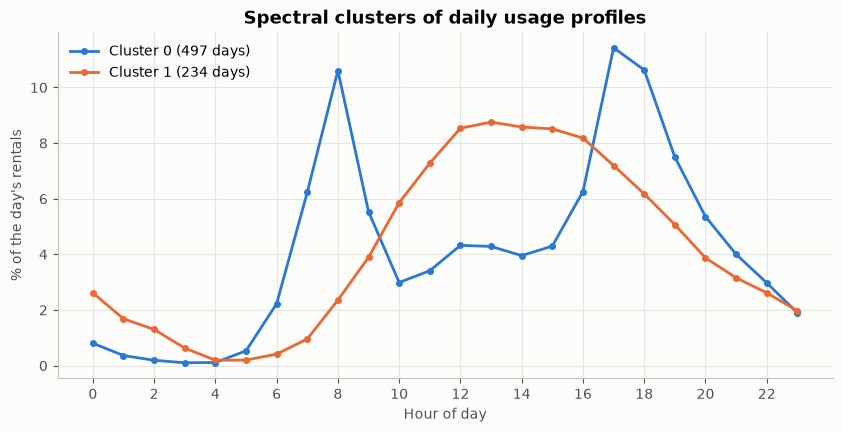

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for k in range(2):
    ax.plot(range(24), shape[daily["spectral"].values == k].mean() * 100, marker="o", markersize=4,
            color=PALETTE[k], label=f"Cluster {k} ({(daily['spectral'] == k).sum()} days)")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("% of the day's rentals")
ax.set_title("Spectral clusters of daily usage profiles")
ax.legend()
save_fig(fig, "04_spectral_profiles")
plt.show()

Spectral clustering separates **commuter days** (two sharp peaks) from **leisure days** (one midday hump) almost perfectly — without being given the calendar. The few disagreements are mostly public holidays that look like weekends, or bad-weather days with unusual shapes.

## 3. Document clustering
The UCI dataset has no text, so we use a small **illustrative corpus of 60 rider feedback comments** (`data/raw/rider_feedback.csv`, written for this project) to show the standard pipeline:

**text → TF-IDF vectors → (LSA) → K-means → inspect top terms per cluster**

*TF-IDF* gives high weight to words that are frequent in one document but rare across the corpus.

In [6]:
docs = pd.read_csv(RAW / "rider_feedback.csv")
print(len(docs), "documents")
docs.sample(5, random_state=3)

60 documents


,id,feedback,theme
47,48,Rebalancing of bikes between stations is too slow,stations
18,19,The basket was broken and the bell was missing,maintenance
56,57,The new protected lane on the bridge feels ver...,safety
13,14,Brakes on my bike were loose and felt unsafe,maintenance
37,38,Station was full so I could not return my bike...,stations


In [7]:
docs["theme"].value_counts()

theme
pricing        12
maintenance    12
app            12
stations       12
safety         12
Name: count, dtype: int64

In [8]:
# Short texts give very sparse TF-IDF vectors, so we use Latent Semantic Analysis (LSA):
# TF-IDF -> TruncatedSVD (10 latent "topics") -> L2-normalise -> K-means.
tfidf = TfidfVectorizer(stop_words="english", sublinear_tf=True)
D = tfidf.fit_transform(docs["feedback"])
print("TF-IDF matrix (documents × terms):", D.shape)

lsa = make_pipeline(TruncatedSVD(10, random_state=0), Normalizer())
L = lsa.fit_transform(D)

sil = {k: silhouette_score(L, KMeans(k, n_init=50, random_state=0).fit_predict(L)) for k in range(2, 9)}
pd.Series(sil, name="silhouette").round(3).to_frame().T

TF-IDF matrix (documents × terms): (60, 195)


,2,3,4,5,6,7,8
silhouette,0.145,0.202,0.239,0.28,0.301,0.339,0.347


In [9]:
k_doc = 5
km_doc = KMeans(k_doc, n_init=50, random_state=0).fit(L)
docs["cluster"] = km_doc.labels_

# top terms: map cluster centres back from LSA space to term space
svd = lsa.named_steps["truncatedsvd"]
centres_terms = svd.inverse_transform(km_doc.cluster_centers_)
terms = np.array(tfidf.get_feature_names_out())
top_terms = {k: terms[np.argsort(centres_terms[k])[::-1][:6]] for k in range(k_doc)}
for k in range(k_doc):
    print(f"Cluster {k} ({(docs.cluster == k).sum():2d} docs): {', '.join(top_terms[k])}")

print("\nAgreement with the written theme labels (ARI):",
      round(adjusted_rand_score(docs["theme"], docs["cluster"]), 3))
pd.crosstab(docs["theme"], docs["cluster"])

Cluster 0 (13 docs): bike, unsafe, lane, riding, dangerous, rain
Cluster 1 (11 docs): app, unlock, code, payment, map, update
Cluster 2 (12 docs): station, near, dock, morning, bike, bikes
Cluster 3 ( 7 docs): membership, price, annual, expensive, discount, students
Cluster 4 (17 docs): ride, broken, stations, bikes, need, repair

Agreement with the written theme labels (ARI): 0.469


cluster,0,1,2,3,4
theme,,,,,
app,0,11,1,0,0
maintenance,3,0,2,0,7
pricing,0,0,0,7,5
safety,10,0,0,0,2
stations,0,0,9,0,3


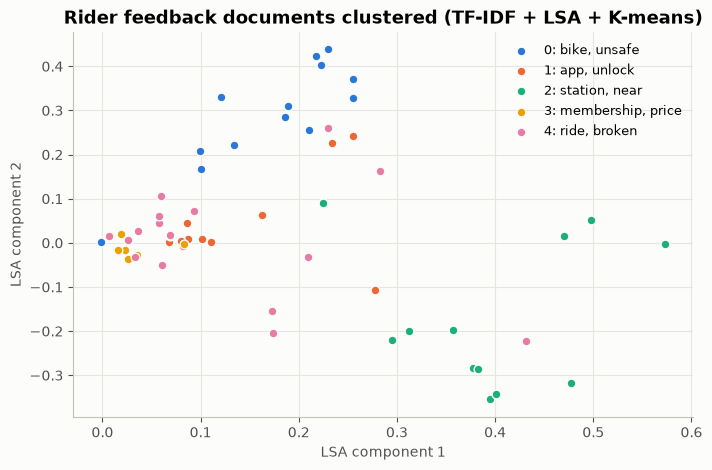

In [10]:
# Visualise in 2-D using the first two LSA components
xy = TruncatedSVD(2, random_state=0).fit_transform(D)
fig, ax = plt.subplots(figsize=(8, 5))
for k in range(k_doc):
    ax.scatter(*xy[docs.cluster == k].T, s=40, color=PALETTE[k], label=f"{k}: {', '.join(top_terms[k][:2])}",
               edgecolor="#fcfcfb")
ax.set_xlabel("LSA component 1")
ax.set_ylabel("LSA component 2")
ax.set_title("Rider feedback documents clustered (TF-IDF + LSA + K-means)")
ax.legend(fontsize=9, loc="best")
save_fig(fig, "04_document_clusters")
plt.show()

**Reading the result**
- Clusters for the **app**, **road safety** and **stations/docks** themes are clean (9–11 of 12 documents each), and their top terms make the theme obvious.
- **Pricing** and **maintenance** are partly mixed into a broader cluster. Many of those comments share generic words ("bike", "ride", "need") and contain only one or two distinctive words.
- Overall agreement with the written labels is moderate (ARI ≈ 0.47). This is typical for **very short documents**: each comment has only 5–10 words, so TF-IDF vectors are sparse. More text per document, or word embeddings, would improve it.

## 4. Minimum Spanning Tree (MST) clustering
1. Treat each day as a node in a complete graph with edge weight = Euclidean distance.
2. Build the **MST** — the tree connecting all nodes with minimum total edge length (Kruskal/Prim).
3. **Delete the k − 1 longest edges** → the tree splits into *k* connected components = clusters.

MST clustering is closely related to *single-linkage* hierarchical clustering.

In [11]:
dist = squareform(pdist(X))
mst = minimum_spanning_tree(dist).toarray()
edges = np.argwhere(mst > 0)
weights = mst[mst > 0]
print("MST edges:", len(weights), "(= n − 1)")

def mst_clusters(mst, k):
    m = mst.copy()
    if k > 1:
        cut = np.sort(m[m > 0])[-(k - 1)]
        m[m >= cut] = 0
    return connected_components(m, directed=False)[1]

for k in [2, 3, 4, 6]:
    labels = mst_clusters(mst, k)
    print(f"k = {k}: cluster sizes = {sorted(np.bincount(labels).tolist(), reverse=True)}")

MST edges: 730 (= n − 1)
k = 2: cluster sizes = [730, 1]
k = 3: cluster sizes = [729, 1, 1]
k = 4: cluster sizes = [728, 1, 1, 1]
k = 6: cluster sizes = [724, 3, 1, 1, 1, 1]


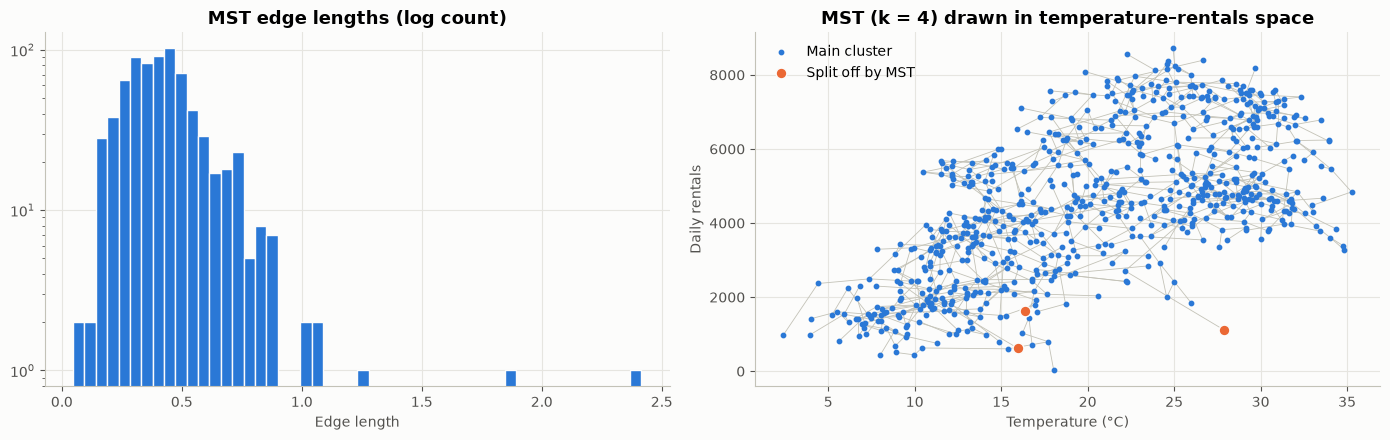

,temp,humidity,windspeed,cnt,weather
date,,,,,
2011-02-19,16.37,18.83,34.00,1635,Clear
2011-03-10,15.95,0.00,17.55,623,Rain/Snow
2011-08-27,27.88,85.00,25.17,1115,Mist/Cloudy


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(weights, bins=50, color=PALETTE[0], edgecolor="#fcfcfb")
axes[0].set_yscale("log")
axes[0].set_xlabel("Edge length")
axes[0].set_title("MST edge lengths (log count)")

labels = mst_clusters(mst, 4)
big = np.bincount(labels).argmax()
for i, j in edges:
    axes[1].plot(daily["temp"].iloc[[i, j]], daily["cnt"].iloc[[i, j]], color="#c3c2b7", linewidth=0.6, zorder=1)
axes[1].scatter(daily["temp"], daily["cnt"], s=10, color=PALETTE[0], zorder=2, label="Main cluster")
iso = labels != big
axes[1].scatter(daily["temp"][iso], daily["cnt"][iso], s=60, color=PALETTE[1], zorder=3,
                edgecolor="#fcfcfb", label="Split off by MST")
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Daily rentals")
axes[1].set_title("MST (k = 4) drawn in temperature–rentals space")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "04_mst")
plt.show()
daily.loc[iso, features + ["weather"]]

Daily weather–demand data forms one continuous cloud, so cutting the longest MST edges does not split it into big groups — instead it **isolates a few extreme days** (very windy or very low-demand storm days). This is a known property of MST/single-linkage clustering and makes it a natural outlier detector (see §7).

## 5. Model-based clustering and the EM algorithm
Model-based clustering assumes the data come from a **mixture of probability distributions**, usually Gaussians:
$$p(x) = \sum_{k=1}^{K} \pi_k \, \mathcal N(x \mid \mu_k, \Sigma_k)$$
The parameters are estimated by maximum likelihood using **Expectation–Maximization (EM)**:
- **E-step:** compute each point's *responsibility* $\gamma_{ik} = P(\text{cluster } k \mid x_i)$ using current parameters.
- **M-step:** update $\pi_k, \mu_k, \Sigma_k$ as responsibility-weighted averages.
- Repeat until the log-likelihood stops increasing (it never decreases).

### 5.1 EM from scratch: 1-D mixture of two Gaussians on daily rentals

In [13]:
x = daily["cnt"].values.astype(float)

# initial guesses
pi, mu, sd = np.array([0.5, 0.5]), np.array([2000.0, 6000.0]), np.array([1000.0, 1000.0])
history = []
for it in range(200):
    # E-step
    dens = pi * stats.norm.pdf(x[:, None], mu, sd)          # n × 2
    ll = np.log(dens.sum(axis=1)).sum()
    gamma = dens / dens.sum(axis=1, keepdims=True)
    # M-step
    nk = gamma.sum(axis=0)
    pi = nk / len(x)
    mu = (gamma * x[:, None]).sum(axis=0) / nk
    sd = np.sqrt((gamma * (x[:, None] - mu) ** 2).sum(axis=0) / nk)
    history.append(ll)
    if it > 0 and abs(history[-1] - history[-2]) < 1e-6:
        break

print(f"Converged after {it + 1} iterations")
print("weights:", pi.round(3), "| means:", mu.round(0), "| std devs:", sd.round(0))

# sklearn's EM, started from the same means (its starting variances come from a k-means step, so they differ)
gm_same = GaussianMixture(2, means_init=[[2000], [6000]], random_state=0).fit(x.reshape(-1, 1))
print("sklearn (means 2000/6000) weights:", gm_same.weights_.round(3), "| means:", gm_same.means_.ravel().round(0))

# a different starting point
gm_other = GaussianMixture(2, means_init=[[3000], [6000]], random_state=0).fit(x.reshape(-1, 1))
print("sklearn (means 3000/6000) weights:", gm_other.weights_.round(3), "| means:", gm_other.means_.ravel().round(0))
print(f"\nTotal log-likelihood — ours: {history[-1]:.1f} | sklearn A: {gm_same.score(x.reshape(-1, 1)) * len(x):.1f}"
      f" | sklearn B: {gm_other.score(x.reshape(-1, 1)) * len(x):.1f}")

Converged after 138 iterations
weights: [0.136 0.864] | means: [1631. 4956.] | std devs: [ 558. 1669.]
sklearn (means 2000/6000) weights: [0.381 0.619] | means: [2722. 5602.]
sklearn (means 3000/6000) weights: [0.493 0.507] | means: [3075. 5893.]

Total log-likelihood — ours: -6545.8 | sklearn A: -6557.9 | sklearn B: -6558.3


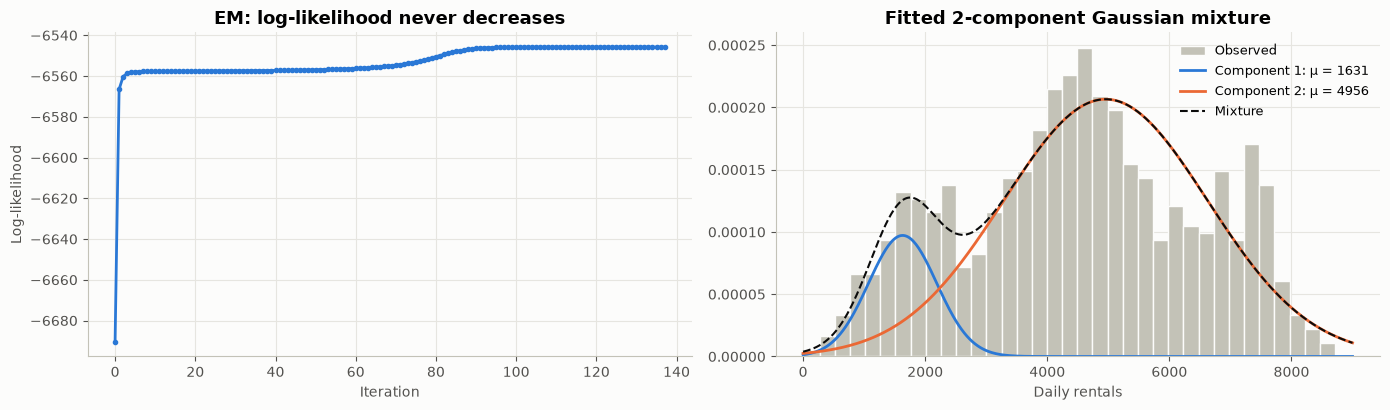

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(history, color=PALETTE[0], marker="o", markersize=3)
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Log-likelihood")
axes[0].set_title("EM: log-likelihood never decreases")

xs = np.linspace(0, 9000, 400)
axes[1].hist(x, bins=35, density=True, color="#c3c2b7", edgecolor="#fcfcfb", label="Observed")
for k in range(2):
    axes[1].plot(xs, pi[k] * stats.norm.pdf(xs, mu[k], sd[k]), color=PALETTE[k],
                 label=f"Component {k + 1}: μ = {mu[k]:.0f}")
axes[1].plot(xs, sum(pi[k] * stats.norm.pdf(xs, mu[k], sd[k]) for k in range(2)),
             color="#0b0b0b", linestyle="--", linewidth=1.5, label="Mixture")
axes[1].set_xlabel("Daily rentals")
axes[1].set_title("Fitted 2-component Gaussian mixture")
axes[1].legend(fontsize=9)
fig.tight_layout()
save_fig(fig, "04_em_from_scratch")
plt.show()

**Important property of EM:** it only guarantees a **local** maximum of the likelihood. Different starting values (and sklearn's different variance initialisation) converge to different solutions; our hand-written run reached the highest log-likelihood here. In practice we run EM from several starts (`n_init`) and keep the best.

Our solution finds a small **low-demand component** (~14% of days, mean ≈ 1,600 rides) and a large **normal component** (mean ≈ 5,000 rides).

In [15]:
# Which days belong to which component?
daily["em_comp"] = np.where(gamma[:, 1] > 0.5, "High-demand", "Low-demand")
pd.crosstab(daily["season"], daily["em_comp"]).reindex(["Spring", "Summer", "Fall", "Winter"])

em_comp,High-demand,Low-demand
season,,
Spring,90,91
Summer,168,16
Fall,185,3
Winter,172,6


### 5.2 Multivariate Gaussian Mixture Model — choosing *K* with BIC
**BIC** = −2·log L + p·log n rewards fit but penalises extra parameters; lower is better. We compare several *K* values and covariance structures.

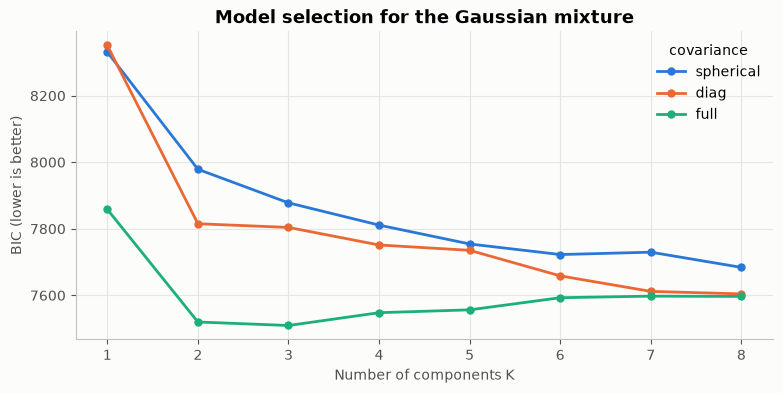

Best model: full covariance with K = 3


In [16]:
bic = pd.DataFrame({cov: [GaussianMixture(k, covariance_type=cov, random_state=0, n_init=3).fit(X).bic(X)
                          for k in range(1, 9)]
                    for cov in ["spherical", "diag", "full"]}, index=range(1, 9))

fig, ax = plt.subplots(figsize=(9, 4))
for i, cov in enumerate(bic.columns):
    ax.plot(bic.index, bic[cov], marker="o", markersize=5, color=PALETTE[i], label=cov)
ax.set_xlabel("Number of components K")
ax.set_ylabel("BIC (lower is better)")
ax.set_title("Model selection for the Gaussian mixture")
ax.legend(title="covariance")
save_fig(fig, "04_gmm_bic")
plt.show()
best_cov, best_k = bic.stack().idxmin()[::-1]
print("Best model:", best_cov, "covariance with K =", best_k)

In [17]:
gmm = GaussianMixture(best_k, covariance_type=best_cov, random_state=0, n_init=5).fit(X)
daily["gmm"] = gmm.predict(X)
gmm_profile = daily.groupby("gmm")[features].mean().round(1)
gmm_profile["days"] = daily["gmm"].value_counts().sort_index()
gmm_profile

,temp,humidity,windspeed,cnt,days
gmm,,,,,
0,27.9,65.6,12.0,5719.0,283
1,17.0,74.7,13.9,2969.9,170
2,14.6,52.7,15.7,4206.2,278


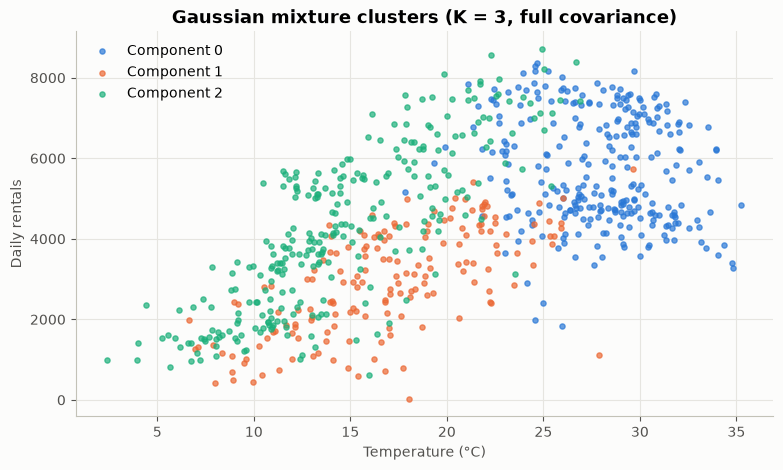

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for k in range(best_k):
    d = daily[daily.gmm == k]
    ax.scatter(d["temp"], d["cnt"], s=14, alpha=0.7, color=PALETTE[k], label=f"Component {k}")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Daily rentals")
ax.set_title(f"Gaussian mixture clusters (K = {best_k}, {best_cov} covariance)")
ax.legend()
save_fig(fig, "04_gmm_clusters")
plt.show()

## 6. Hierarchical agglomerative clustering
Start with every point as its own cluster and repeatedly **merge the two closest clusters**. The *linkage* rule defines "closest":

| Linkage | Merge cost |
|---|---|
| Single | closest pair of points (≈ MST clustering) |
| Complete | farthest pair of points |
| Average | mean pairwise distance |
| **Ward** | increase in within-cluster sum of squares |

**Model-based view:** Ward's method is the hierarchical agglomerative form of model-based clustering for a Gaussian mixture with equal, spherical covariances — each merge is the one that *least decreases the classification likelihood*. (Model-based hierarchical clustering, as in R's `mclust`, generalises this to other covariance models.)

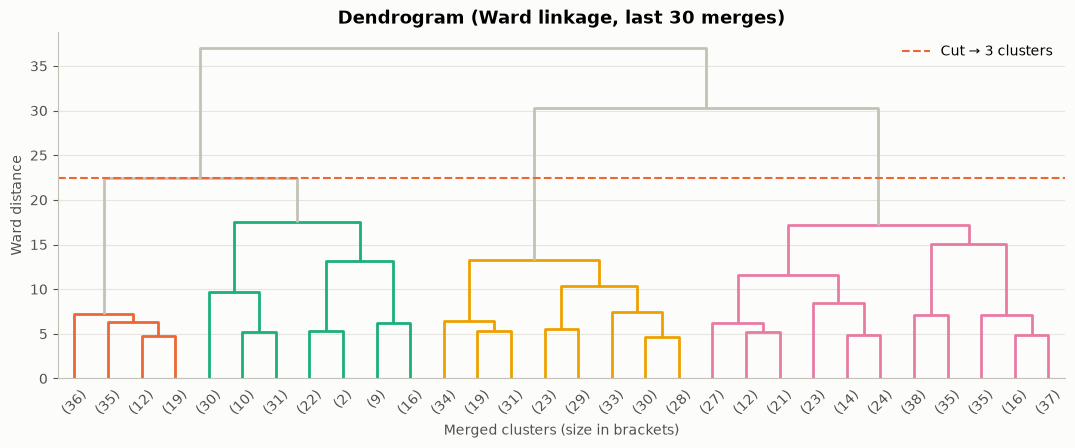

In [19]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-3, 2],
           above_threshold_color="#c3c2b7", ax=ax)
ax.axhline(Z[-3, 2], color=PALETTE[1], linestyle="--", linewidth=1.5, label="Cut → 3 clusters")
ax.set_xlabel("Merged clusters (size in brackets)")
ax.set_ylabel("Ward distance")
ax.set_title("Dendrogram (Ward linkage, last 30 merges)")
ax.legend()
ax.grid(axis="x", visible=False)
save_fig(fig, "04_dendrogram")
plt.show()

In [20]:
comp = []
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X)
    comp.append({"linkage": link, "silhouette": silhouette_score(X, lab),
                 "cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
pd.DataFrame(comp).round(3)

,linkage,silhouette,cluster sizes
0,ward,0.197,"[282, 227, 222]"
1,complete,0.301,"[681, 48, 2]"
2,average,0.465,"[729, 1, 1]"
3,single,0.465,"[729, 1, 1]"


In [21]:
daily["hier"] = fcluster(Z, t=3, criterion="maxclust")
hier_profile = daily.groupby("hier")[features].mean().round(1)
hier_profile["days"] = daily["hier"].value_counts().sort_index()
hier_profile

,temp,humidity,windspeed,cnt,days
hier,,,,,
1,15.5,53.2,18.1,3337.8,222
2,27.0,60.4,11.6,6410.0,227
3,18.7,72.3,12.3,3888.7,282


Ward gives balanced, interpretable groups (e.g. *cold low-demand days*, *warm high-demand days*, *humid/rainy low-demand days*). Single linkage, like MST, mostly chains everything into one large cluster and peels off a few outliers.

## 7. Outlier detection using clustering
Points that do not fit any cluster well are outliers. Three cluster-based scores:
1. **GMM log-likelihood** — days with very low density under the fitted mixture.
2. **K-means distance** — days far from their nearest centroid.
3. **DBSCAN** — points not in any dense region are labelled *noise* (−1).

In [22]:
daily["gmm_score"] = gmm.score_samples(X)
km = KMeans(3, n_init=10, random_state=0).fit(X)
daily["km_dist"] = np.min(km.transform(X), axis=1)
daily["dbscan"] = DBSCAN(eps=1.0, min_samples=8).fit_predict(X)

q = 0.02  # flag the most extreme 2%
flags = pd.DataFrame({
    "GMM": daily["gmm_score"] < daily["gmm_score"].quantile(q),
    "K-means": daily["km_dist"] > daily["km_dist"].quantile(1 - q),
    "DBSCAN": daily["dbscan"] == -1,
})
daily["n_flags"] = flags.sum(axis=1)
print(flags.sum().to_string())
print("Flagged by all three methods:", (daily["n_flags"] == 3).sum())

GMM        15
K-means    15
DBSCAN     15
Flagged by all three methods: 7


In [23]:
outliers = daily[daily["n_flags"] >= 2].sort_values("gmm_score")
outliers[["weekday", "weather", "temp", "humidity", "windspeed", "cnt", "n_flags"]]

,weekday,weather,temp,humidity,windspeed,cnt,n_flags
date,,,,,,,
2011-03-10,Thu,Rain/Snow,15.95,0.00,17.55,623,3
2011-02-19,Sat,Clear,16.37,18.83,34.00,1635,3
2011-08-27,Sat,Mist/Cloudy,27.88,85.00,25.17,1115,3
2011-06-02,Thu,Clear,29.28,30.33,19.88,4968,3
2011-04-04,Mon,Clear,23.51,42.62,25.83,3115,2
2012-02-12,Sun,Clear,5.23,46.58,27.42,1529,2
2012-10-28,Sun,Mist/Cloudy,19.58,69.46,26.67,4459,3
2011-10-20,Thu,Clear,19.56,63.62,28.29,4195,3
2012-03-08,Thu,Clear,21.61,56.75,29.58,5382,3


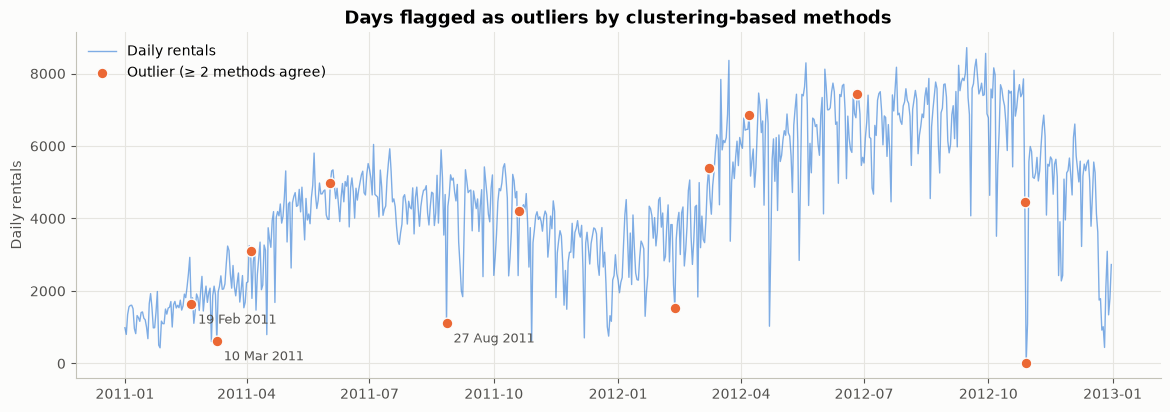

In [24]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily.index, daily["cnt"], color=PALETTE[0], linewidth=1, alpha=0.6, label="Daily rentals")
ax.scatter(outliers.index, outliers["cnt"], color=PALETTE[1], s=60, zorder=3,
           edgecolor="#fcfcfb", label="Outlier (≥ 2 methods agree)")
for d in outliers.nsmallest(3, "gmm_score").index:
    ax.annotate(d.strftime("%d %b %Y"), (d, daily.loc[d, "cnt"]), xytext=(5, -14),
                textcoords="offset points", fontsize=9, color="#52514e")
ax.set_ylabel("Daily rentals")
ax.set_title("Days flagged as outliers by clustering-based methods")
ax.legend(loc="upper left")
save_fig(fig, "04_outliers")
plt.show()

The flagged days are explainable:
- **10 Mar 2011** has **humidity = 0%** all day, which is physically impossible — a **data-quality error** in the source file that the clustering methods caught.
- **27 Aug 2011** is **Hurricane Irene** (high humidity, strong wind, low demand) and **28 Oct 2012** is the windy day before Hurricane Sandy's landfall.
- Most other flags are **very windy days** (windspeed > 25 km/h) or very dry days.

**Limitation:** 29 Oct 2012 (Sandy's landfall, only 22 rentals) is *not* flagged. Its weather averages look like an ordinary rainy day, and a low count alone is not extreme enough in 4-D space. Detecting it needs a residual-based check ("demand far below what the weather predicts"), which is why we combine several methods.

## Summary
| Method | Main finding |
|---|---|
| Spectral | Recovered **working vs non-working days** from hourly shapes alone |
| Document | TF-IDF + LSA recovers **app, safety and station** themes well; short texts limit accuracy (ARI ≈ 0.47) |
| MST | Data is one continuous cloud; longest edges isolate **extreme days** |
| EM / GMM | EM finds a **low-demand** and a **normal** regime (local optima matter); BIC selects K = 3 weather–demand groups |
| Hierarchical | Ward linkage gives balanced weather–demand groups; single linkage only peels off outliers |
| Outliers | Methods agree on **Hurricane Irene**, very windy days and a **humidity = 0 data error** |